## Jack Chou

# Assignment 4: Fed surprises, omitted variables and autoregression

This worked example is built on Kuttner (2001), *Monetary policy surprises and interest rates: Evidence from the Fed funds futures market*. It uses omitted variable bias and autoregressive models, with confidence intervals and hypothesis tests (Sections 3.3 and 3.6) where they come up.

### Background

Kuttner asks how much Treasury yields move on the day the Fed changes its target for the federal funds rate. The difficulty is that markets often see a move coming, and a yield set in a forward-looking market should already reflect a change that everyone expected. Kuttner uses fed funds futures to separate the two. The futures rate is the market's forecast of the average funds rate for the month, so the scaled one-day change in the futures rate on the day of the move measures the part of the move that was news (his eq. 7):

$$\Delta \tilde r^u_t = \frac{m}{m-t}\left(f^0_{s,t} - f^0_{s,t-1}\right), \qquad \Delta \tilde r^e_t = \Delta \tilde r_t - \Delta \tilde r^u_t,$$

where $m$ is the number of days in the month and $t$ is the day of the move. So every target change splits into an expected part and a surprise,

$$\Delta \tilde r_t = \Delta \tilde r^e_t + \Delta \tilde r^u_t .$$

Table 2 of the paper lists all 42 target changes from June 1989 to February 2000 with this split. Two regression models appear in the paper. The older one, from Cook and Hahn (1989), regresses the one-day change in a yield $R$ (in basis points) on the whole target change (in percentage points):

$$\Delta R_t = \beta_0 + \beta' \Delta \tilde r_t + \epsilon_t . \qquad (1)$$

Kuttner's version uses the two parts as separate predictors:

$$\Delta R_t = \beta_0 + \beta_e \Delta \tilde r^e_t + \beta_u \Delta \tilde r^u_t + \epsilon_t . \qquad (8)$$

We keep Kuttner's equation numbers but change his notation to match the notes. He writes the intercept as $\alpha$, the slope in (1) as $\beta$, and the slopes in (8) as $\beta_1, \beta_2$. We write the intercept as $\beta_0$ (instead of $\alpha$ which was used in the literature), use $\beta'$ for the single-predictor slope (as in Section 4.2), and label the two slopes $\beta_e$ and $\beta_u$.

**Data:** The 42 rows of Table 2 below are real. Kuttner does not publish the yield change for each event, so where we need those we simulate them from model (8), using his Table 3 estimates of $\beta_0$, $\beta_e$, $\beta_u$ and $\sigma_\epsilon$. Every yield change in this notebook is simulated.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
%config InlineBackend.figure_format = 'svg'

rng = np.random.default_rng(2001)

In [3]:
# Kuttner (2001), Table 2: actual, expected and unexpected changes in the Fed funds target (basis points)
table2 = [
    ("1989-06-06", 0, -25, -24,  -1), ("1989-07-07", 1, -25, -22,  -3), ("1989-07-27", 0, -25, -25,   0),
    ("1989-10-18", 0, -25, -25,   0), ("1989-11-06", 0, -25, -29,   4), ("1989-12-20", 1, -25,  -8, -17),
    ("1990-07-13", 0, -25, -11, -14), ("1990-10-29", 0, -25,   6, -31), ("1990-11-14", 1, -25, -29,   4),
    ("1990-12-07", 0, -25,   2, -27), ("1990-12-18", 1, -25,  -4, -21), ("1991-01-08", 0, -25,  -7, -18),
    ("1991-02-01", 0, -50, -25, -25), ("1991-03-08", 0, -25,  -9, -16), ("1991-04-30", 0, -25,  -8, -17),
    ("1991-08-06", 0, -25, -10, -15), ("1991-09-13", 0, -25, -20,  -5), ("1991-10-31", 0, -25, -20,  -5),
    ("1991-11-06", 1, -25, -13, -12), ("1991-12-06", 0, -25, -16,  -9), ("1991-12-20", 0, -50, -22, -28),
    ("1992-04-09", 0, -25,  -1, -24), ("1992-07-02", 1, -50, -14, -36), ("1992-09-04", 0, -25,  -3, -22),
    ("1994-02-04", 1,  25,  13,  12), ("1994-03-22", 1,  25,  28,  -3), ("1994-04-18", 0,  25,  15,  10),
    ("1994-05-17", 1,  50,  37,  13), ("1994-08-16", 1,  50,  36,  14), ("1994-11-15", 1,  75,  61,  14),
    ("1995-02-01", 1,  50,  45,   5), ("1995-07-06", 1, -25, -24,  -1), ("1995-12-19", 1, -25, -15, -10),
    ("1996-01-31", 1, -25, -18,  -7), ("1997-03-25", 1,  25,  22,   3), ("1998-09-29", 1, -25, -25,   0),
    ("1998-10-15", 0, -25,   1, -26), ("1998-11-17", 1, -25, -19,  -6), ("1999-06-30", 1,  25,  29,  -4),
    ("1999-08-24", 1,  25,  23,   2), ("1999-11-16", 1,  25,  16,   9), ("2000-02-02", 1,  25,  30,  -5),
]
df = pd.DataFrame(table2, columns=["date", "fomc", "actual", "expected", "unexpected"])
df["date"] = pd.to_datetime(df.date)
df[["actual", "expected", "unexpected"]] /= 100 # convert to percentage points, as in Kuttner's regressions
df["post94"] = df.date >= "1994-02-04" # the Fed began announcing its decisions in February 1994

a = df.actual.to_numpy()
e = df.expected.to_numpy()
u = df.unexpected.to_numpy()
N = len(df)
assert np.allclose(a, e + u)
print(N, "target changes;", df.post94.sum(), "from February 1994 on")

42 target changes; 18 from February 1994 on


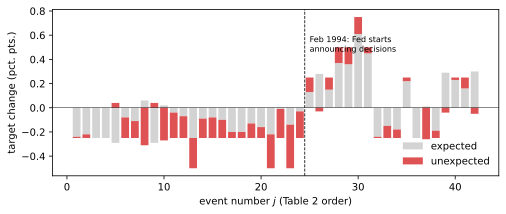

In [4]:
fig, ax = plt.subplots(figsize=(8, 3))
j = np.arange(1, N + 1)
ax.bar(j, e, color="lightgray", label="expected")
ax.bar(j, u, bottom=np.where(np.sign(u) == np.sign(e), e, 0), color="C3", alpha=0.8, label="unexpected")
ax.axvline(24.5, color="k", lw=0.8, ls="--")
ax.text(25, 0.6, "Feb 1994: Fed starts\nannouncing decisions", fontsize=8, va="top")
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel("event number $j$ (Table 2 order)")
ax.set_ylabel("target change (pct. pts.)")
ax.legend(frameon=False, loc="lower right")
plt.show()

Most of the 1989–1992 cuts were at least partly a surprise, and almost every surprise in that stretch was negative. The 1994–1995 hikes were mostly expected.

We will use two least squares helpers throughout, written with the formulas from Section 3.4: the slope, the intercept, $\hat\sigma_\epsilon$, and $\mathrm{se}(\hat\beta_1) = \hat\sigma_\epsilon/\sqrt{S_{xx}}$.

In [5]:
def fit(x, y):
    # single-predictor least squares: returns beta0_hat, beta1_hat, se(beta1_hat)
    Sxx = np.sum((x - x.mean())**2)
    b1 = np.sum((x - x.mean()) * (y - y.mean())) / Sxx
    b0 = y.mean() - b1 * x.mean()
    r = y - (b0 + b1 * x)
    sigma_hat = np.sqrt(np.sum(r**2) / (len(x) - 2))
    return b0, b1, sigma_hat / np.sqrt(Sxx)


def fit2(x1, x2, y):
    # two-predictor least squares: returns [beta0_hat, beta1_hat, beta2_hat]
    X = np.column_stack([np.ones_like(x1), x1, x2])
    return np.linalg.lstsq(X, y, rcond=None)[0]

In [6]:
# Kuttner Table 3 (model 8): intercept, anticipated, unanticipated, SE  -- and Table 1 (model 1) slope
table3 = pd.DataFrame({
    "maturity": ["3 month", "6 month", "12 month", "2 year", "5 year", "10 year", "30 year"],
    "beta_0": [-0.7, -2.5, -2.2, -2.8, -2.4, -2.4, -2.5],
    "beta_e": [ 4.4,  0.6, -2.3, -0.4, -5.8, -7.4, -8.2],
    "beta_u": [79.1, 71.6, 71.6, 61.4, 48.1, 31.5, 19.4],
    "sigma": [ 7.1,  6.3,  6.9,  7.8,  8.6,  7.8,  6.5],
    "table1_slope": [26.8, 21.9, 19.8, 18.2, 10.4, 4.3, 0.1],
}).set_index("maturity")


def simulate_yield(maturity, rng):
    # one simulated set of 42 one-day yield changes (bp) from model (8) with Table 3 parameters
    p = table3.loc[maturity]
    return p.beta_0 + p.beta_e * e + p.beta_u * u + rng.normal(0, p.sigma, N)

table3

,beta_0,beta_e,beta_u,sigma,table1_slope
maturity,,,,,
3 month,-0.7,4.4,79.1,7.1,26.8
6 month,-2.5,0.6,71.6,6.3,21.9
12 month,-2.2,-2.3,71.6,6.9,19.8
2 year,-2.8,-0.4,61.4,7.8,18.2
5 year,-2.4,-5.8,48.1,8.6,10.4
10 year,-2.4,-7.4,31.5,7.8,4.3
30 year,-2.5,-8.2,19.4,6.5,0.1


## Question 1: Did the Fed lose its grip on long-term rates?

Kuttner's Table 1 fits model (1) to the 42 events. By that model, a 1 percentage point rise in the target goes with a 26.8 bp rise in the 3-month bill rate and a 10.4 bp rise in the 5-year yield. For the 10-year yield the slope is 4.3 bp ($t = 1.0$), and for the 30-year yield it is 0.1 bp ($t = 0.0$). Taken at face value, the Fed barely moves long-term rates. Table 3 fits model (8) to the same events and finds that the 30-year yield rises 19.4 bp per point of *surprise* ($t = 2.3$), while the 3-month rate rises 79.1 bp.

**(a)** Without any calculation, explain how model (1) can give a slope near zero for the 30-year yield even though model (8) is true with $\beta_u = 19.4$.

**(b)** Assume model (8) is the true model. Find the slope $\beta'$ of model (1) in terms of $\beta_e$, $\beta_u$ and a quantity you can compute from Table 2.

**(c)** Using only Table 2 and the Table 3 coefficients, predict all seven slopes in Table 1. How close do you get?

**(d)** Simulate 5-year yield changes from model (8) and fit both models. Remake Kuttner's Figure 2. Then repeat the simulation many times. Which number is the model (1) slope an unbiased estimate of?

**(e)** Cook and Hahn's 1974–1979 data gave a 3-month slope of 55 bp, twice the 1989–2000 value. Some readers took this as a sign that the Fed's influence on markets had weakened. Use your formula from (b) to offer another explanation, and check it by splitting Table 2 at February 1994, when the Fed began announcing its decisions.

### Solution

**(a)** Model (1) has one predictor, $\Delta\tilde r = \Delta\tilde r^e + \Delta\tilde r^u$, so it forces the expected part and the surprise to have the same effect. They don't. A move the market already expected was priced in the day before, so it should barely move yields ($\beta_e \approx 0$), while a surprise does ($\beta_u > 0$). In 1989–2000 most of a typical target change was expected (the gray bars above), so most of the variation in $\Delta\tilde r$ comes from a part with no effect, and the slope is pulled towards $\beta_e$. This is the situation of Section 4.2: model (1) leaves out a predictor ($\Delta\tilde r^u$) that matters and is correlated with the one it keeps. Kuttner calls this an errors-in-variables problem: the "true" predictor (the surprise) is measured with noise (the expected part) added on.

**(b)** Since $\Delta\tilde r^e = \Delta\tilde r - \Delta\tilde r^u$, model (8) can be rewritten with $X_1 = \Delta\tilde r$ and $X_2 = \Delta\tilde r^u$ as predictors:

$$\Delta R = \beta_0 + \beta_e\,\Delta\tilde r + (\beta_u - \beta_e)\,\Delta\tilde r^u + \epsilon .$$

From Section 4.2, if we drop $X_2$, the single-predictor coefficient of $X_1$ is

$$\beta' = \beta_1 + \beta_2\big(E[X_2 \mid X_1 = x+1] - E[X_2 \mid X_1 = x]\big).$$

Here $\beta_1 = \beta_e$, $\beta_2 = \beta_u - \beta_e$, and the change in $E[\Delta\tilde r^u \mid \Delta\tilde r]$ per unit of $\Delta\tilde r$ is the slope from regressing the surprise on the total change,

$$b = \frac{\mathrm{cov}(\Delta\tilde r, \Delta\tilde r^u)}{\sigma^2_{\Delta\tilde r}} .$$

So

$$\beta' = \beta_e + (\beta_u - \beta_e)\, b = (1-b)\,\beta_e + b\,\beta_u .$$

The same answer comes directly from $\beta' = \mathrm{cov}(\Delta R, \Delta\tilde r)/\sigma^2_{\Delta\tilde r}$, substituting model (8) for $\Delta R$, so it does not rely on $E[X_2\mid X_1]$ being exactly linear. The coefficient $b$ is the share of a typical target change that was a surprise. The model (1) slope is a weighted average of the two responses with weights $1-b$ and $b$. When $\beta_e \approx 0$, it is just $b\,\beta_u$.

In [7]:
b = fit(a, u)[1]
print(f"b = slope of surprise on total change = {b:.3f}")

pred = table3.copy()
pred["predicted_beta_prime"] = (pred.beta_e + (pred.beta_u - pred.beta_e) * b).round(1)
pred["gap"] = (pred.predicted_beta_prime - pred.table1_slope).round(1)
pred[["beta_e", "beta_u", "predicted_beta_prime", "table1_slope", "gap"]]

b = slope of surprise on total change = 0.314


,beta_e,beta_u,predicted_beta_prime,table1_slope,gap
maturity,,,,,
3 month,4.4,79.1,27.9,26.8,1.1
6 month,0.6,71.6,22.9,21.9,1.0
12 month,-2.3,71.6,20.9,19.8,1.1
2 year,-0.4,61.4,19.0,18.2,0.8
5 year,-5.8,48.1,11.1,10.4,0.7
10 year,-7.4,31.5,4.8,4.3,0.5
30 year,-8.2,19.4,0.5,0.1,0.4


**(c)** Only about $b \approx 0.31$ of a typical target change was a surprise. The formula then predicts every slope in Table 1 to within about 1 bp, using nothing but the published Table 2 and Table 3 numbers. For the 30-year yield, $\beta' \approx 0.31 \times 19.4 + 0.69 \times (-8.2) \approx 0.5$. A real response to surprises is cancelled out by a slightly negative response to the expected part. The remaining gaps come from rounding in the published tables and from the noise $\epsilon$ in Kuttner's actual yields, which our prediction leaves out.

**(d)** We simulate one set of 5-year yield changes from model (8) and fit both models.

model (1): slope on actual change = 10.4
model (8): [beta_0, beta_e, beta_u] = [-3.8 -2.3 38.2]


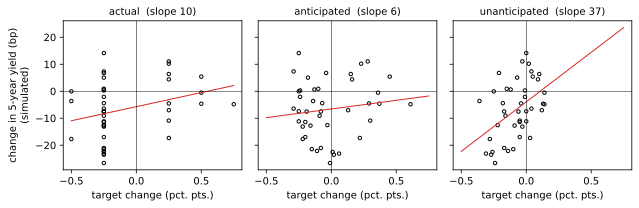

In [8]:
y5 = simulate_yield("5 year", rng)
print("model (1): slope on actual change = %.1f" % fit(a, y5)[1])
print("model (8): [beta_0, beta_e, beta_u] =", fit2(e, u, y5).round(1))

fig, axes = plt.subplots(1, 3, figsize=(9, 3), sharey=True)
for ax, x, name in zip(axes, [a, e, u], ["actual", "anticipated", "unanticipated"]):
    b0, b1, _ = fit(x, y5)
    xx = np.linspace(-0.5, 0.75, 2)
    ax.scatter(x, y5, s=12, facecolors="none", edgecolors="k")
    ax.plot(xx, b0 + b1 * xx, color="C3", lw=1)
    ax.axhline(0, color="k", lw=0.5); ax.axvline(0, color="k", lw=0.5)
    ax.set_title(f"{name}  (slope {b1:.0f})", fontsize=10)
    ax.set_xlabel("target change (pct. pts.)")
axes[0].set_ylabel("change in 5-year yield (bp)\n(simulated)")
plt.tight_layout()
plt.show()

average model (1) slope over 5000 replicates: 11.1
beta_prime from (b): 11.1     beta_u: 48.1


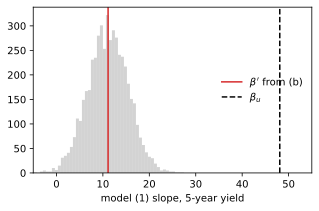

In [9]:
reps = 5000
slopes1 = np.array([fit(a, simulate_yield("5 year", rng))[1] for _ in range(reps)])
p5 = table3.loc["5 year"]
print("average model (1) slope over %d replicates: %.1f" % (reps, slopes1.mean()))
print("beta_prime from (b): %.1f     beta_u: %.1f" % (p5.beta_e + (p5.beta_u - p5.beta_e) * b, p5.beta_u))

plt.figure(figsize=(5, 3))
plt.hist(slopes1, bins=50, color="lightgray")
plt.xlim(-5, 55)
plt.axvline(p5.beta_e + (p5.beta_u - p5.beta_e) * b, color="C3", label=r"$\beta'$ from (b)")
plt.axvline(p5.beta_u, color="k", ls="--", label=r"$\beta_u$")
plt.xlabel("model (1) slope, 5-year yield")
plt.legend(frameon=False, loc="center right")
plt.show()

As in Kuttner's Figure 2, the 5-year yield change has almost no relationship with the actual or anticipated change. It lines up well with the surprise. (With only 42 events, a single dataset estimates $\beta_u$ with a standard error of about 11 bp, so this one replicate's estimate lands somewhat below the true 48.) Across replicates, the model (1) slope is centered on $\beta' \approx 11$, not on $\beta_u = 48$. Least squares is not doing anything wrong: it is an unbiased estimate of the wrong quantity. Collecting more events with the same mix of expected and unexpected moves would make the estimate more precise but would not move it towards $\beta_u$.

**(e)** The formula says $\beta'$ depends on $b$, the share of a move that is a surprise, as well as on how markets react to news ($\beta_e, \beta_u$). If $\beta_e$ and $\beta_u$ stayed the same but the Fed became more predictable, $b$ would fall and so would the model (1) slope.

In [10]:
rows = []
for label, mask in [("Jun 1989 - Sep 1992", ~df.post94), ("Feb 1994 - Feb 2000", df.post94)]:
    b_sub = fit(a[mask], u[mask])[1]
    p3 = table3.loc["3 month"]
    rows.append([label, mask.sum(), round(b_sub, 2), round(p3.beta_e + (p3.beta_u - p3.beta_e) * b_sub, 1)])
pd.DataFrame(rows, columns=["period", "events", "b", "predicted 3-month slope"])

,period,events,b,predicted 3-month slope
0,Jun 1989 - Sep 1992,24,0.71,57.6
1,Feb 1994 - Feb 2000,18,0.24,22.1


Before 1994 the Fed did not announce its decisions, and about 70% of a typical move was a surprise. With Kuttner's $\beta_e$ and $\beta_u$, model (1) would then give a 3-month slope of about 58 bp, close to Cook and Hahn's 55 bp. After 1994 only about a quarter of a move was a surprise, and the predicted slope falls to about 22 bp. So the drop in the model (1) slope can be explained entirely by a change in $b$, i.e. by a more predictable Fed, with no change in how markets react to news. In the 1970s markets often could not tell that a change had happened until the next day (Kuttner, Section 3.3), so it is plausible that $b$ was close to 1 and that model (1) was close to measuring $\beta_u$ directly.

One caution: this assumes $\beta_e$ and $\beta_u$ are the same in both periods. Each half has only 18–24 events, so we cannot check that very well, and with so few observations the two values of $b$ are themselves uncertain.

## Question 2: Could the market have seen the surprises coming?

Kuttner's method treats the futures rate as the market's best forecast. If it is, the surprise $\Delta\tilde r^u$ should be unpredictable from anything known the day before (Krueger and Kuttner, 1996, find futures-based forecasts "efficient" in this sense). In particular, the last surprise should not help predict the next one. Yet in Table 2, 20 of the 24 surprises from 1989 to 1992 are negative, 2 are zero, and only 2 are positive.

Let $u_j$ be the surprise at the $j$-th target change, $j = 1, \dots, 42$. Note that $j$ counts events, not days.

**(a)** Write down an AR(1) model for $u_j$. What value of $\rho$ does market efficiency imply? If the futures rate is also an unbiased forecast, what should the mean $\mu$ of $u_j$ be?

**(b)** Fit the AR(1) model to the surprises $u_j$, and also to the expected changes $e_j$. Plot $u_j$ against $u_{j-1}$, and plot the sample autocorrelation function of $u_j$. Should the expected changes be autocorrelated?

**(c)** Give a 95% confidence interval for $\rho$ and test $\rho = 0$, using $\mathrm{se}(\hat\rho)$ from Section 3.4. The usual formula assumes independent data, which is exactly what is in question here, so check the test by simulation. Generate many series of 42 independent surprises, fit the AR(1) model to each, and look at the distribution of $\hat\rho$. Where does the Hurwicz bias show up?

**(d)** The test in (c) assumes the surprises are stationary. Give an explanation for $\hat\rho > 0$ in which each surprise is unpredictable *given the period it falls in*. Test it by simulation and by fitting each period separately. List any other features of the data that make AR(1) on $j$ a questionable model.

**(e)** Suppose instead that the predictable part of each surprise really was anticipated by traders, and Kuttner's method mislabels it as a surprise. Using Question 1, what would that do to his estimate $\hat\beta_u = 79.1$ for the 3-month bill? Is the result believable?

### Solution

**(a)** The AR(1) model is

$$u_j = \beta_0 + \rho\, u_{j-1} + \epsilon_j, \qquad \epsilon_j \sim \mathrm{Normal}(0, \sigma_\epsilon^2),$$

with $\epsilon_j$ independent of $u_{j-1}, u_{j-2}, \dots$. If the market uses everything it knows, $u_{j-1}$ is known before event $j$ and cannot help predict $u_j$, so $\rho = 0$. For a stationary series $\mu = \beta_0/(1-\rho)$, and an unbiased forecast means the surprises average to zero, so $\mu = 0$ and $\beta_0 = 0$.

**(b)**

surprises u_j : rho_hat = 0.495, beta0_hat = -0.040, se = 0.139
expected e_j  : rho_hat = 0.557, beta0_hat = 0.001, se = 0.136


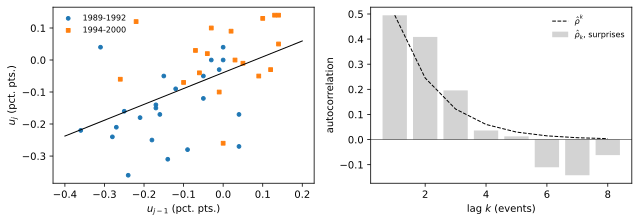

In [11]:
def acf(x, k):
    # sample autocorrelation at lag k (Section 3.5)
    xc = x - x.mean()
    return np.sum(xc[:-k] * xc[k:]) / np.sum(xc**2)


for name, x in [("surprises u_j", u), ("expected e_j", e)]:
    b0, rho_hat, se = fit(x[:-1], x[1:])
    print(f"{name:14s}: rho_hat = {rho_hat:.3f}, beta0_hat = {b0:.3f}, se = {se:.3f}")

rho_u, se_u = fit(u[:-1], u[1:])[1:]
lags = np.arange(1, 9)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
ax = axes[0]
ax.scatter(u[:-1][~df.post94[1:]], u[1:][~df.post94[1:]], s=14, label="1989-1992")
ax.scatter(u[:-1][df.post94[1:]], u[1:][df.post94[1:]], s=14, marker="s", label="1994-2000")
b0, b1, _ = fit(u[:-1], u[1:])
xx = np.linspace(-0.4, 0.2, 2)
ax.plot(xx, b0 + b1 * xx, color="k", lw=1)
ax.set_xlabel("$u_{j-1}$ (pct. pts.)"); ax.set_ylabel("$u_j$ (pct. pts.)")
ax.legend(frameon=False, fontsize=8)
ax = axes[1]
ax.bar(lags, [acf(u, k) for k in lags], color="lightgray", label=r"$\hat\rho_k$, surprises")
ax.plot(lags, rho_u**lags, "k--", lw=1, label=r"$\hat\rho^k$")
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel("lag $k$ (events)"); ax.set_ylabel("autocorrelation")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

Both series have $\hat\rho \approx 0.5$. The sample ACF of the surprises decays roughly like $\hat\rho^k$, as an AR(1) process would, and is close to zero by lag 4. The scatter plot already hints at what is going on: the 1989–1992 points sit in the lower left and the 1994–2000 points near the origin.

Autocorrelated expected changes do not contradict market efficiency. The Fed moves in long runs: a string of cuts in 1989–1992, then hikes in 1994–1995. Traders know this, so the expected part of each move tends to have the same sign as the last one. (Within 1989–1992 alone, the expected changes have $\hat\rho \approx 0$, so this mostly reflects the switch from cuts to hikes.) Efficiency only rules out predictable *surprises*.

**(c)** Using $\mathrm{se}(\hat\rho) = \hat\sigma_\epsilon/\sqrt{S_{xx}}$ from Section 3.4:

In [12]:
T_hat = rho_u / se_u
print(f"rho_hat = {rho_u:.3f}, se = {se_u:.3f}")
print(f"95% CI: [{rho_u - 2 * se_u:.2f}, {rho_u + 2 * se_u:.2f}],  T = {T_hat:.2f}")

# null by simulation: 42 independent Normal surprises with Table 2's standard deviation
reps = 20000
sd_u = u.std(ddof=1)
rho_null = np.array([fit(z[:-1], z[1:])[1] for z in rng.normal(0, sd_u, (reps, N))])
print(f"null: mean rho_hat = {rho_null.mean():.3f}, sd = {rho_null.std():.3f}")
print(f"simulated p-value P(|rho*| >= |rho_hat|) = {np.mean(np.abs(rho_null) >= abs(rho_u)):.4f}")

rho_hat = 0.495, se = 0.139
95% CI: [0.22, 0.77],  T = 3.57
null: mean rho_hat = -0.024, sd = 0.153
simulated p-value P(|rho*| >= |rho_hat|) = 0.0008


true rho = 0.0: average rho_hat = -0.025  (bias -0.025; notes' -2rho/N = -0.000)
true rho = 0.5: average rho_hat = 0.442  (bias -0.058; notes' -2rho/N = -0.024)


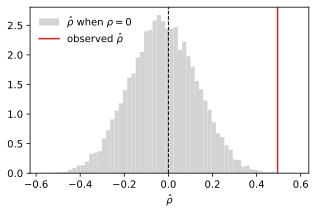

In [13]:
# Hurwicz bias when the true rho is not zero: simulate stationary AR(1) series of length 42
def sim_ar1(rho, N, reps, rng):
    eps = rng.normal(size=(reps, N))
    Y = np.empty((reps, N))
    Y[:, 0] = eps[:, 0] / np.sqrt(1 - rho**2)      # start from the stationary distribution
    for t in range(1, N):
        Y[:, t] = rho * Y[:, t - 1] + eps[:, t]
    return Y


for rho in [0.0, 0.5]:
    est = np.array([fit(z[:-1], z[1:])[1] for z in sim_ar1(rho, N, reps, rng)])
    print(f"true rho = {rho}: average rho_hat = {est.mean():.3f}  (bias {est.mean() - rho:+.3f}; notes' -2rho/N = {-2 * rho / N:+.3f})")

plt.figure(figsize=(5, 3))
plt.hist(rho_null, bins=60, color="lightgray", density=True, label=r"$\hat\rho$ when $\rho=0$")
plt.axvline(rho_u, color="C3", label=r"observed $\hat\rho$")
plt.axvline(0, color="k", ls="--", lw=1)
plt.xlabel(r"$\hat\rho$")
plt.legend(frameon=False)
plt.show()

The confidence interval, roughly $[0.22, 0.77]$, excludes zero, and $T \approx 3.6$. The simulated null distribution agrees: among 20,000 independent series, almost none give $\hat\rho$ as large as 0.50, so $p < 0.001$.

The Hurwicz bias shows up in two places. Under the null, $\hat\rho$ averages about $-0.02$ rather than 0. When the true $\rho$ is 0.5, $\hat\rho$ averages about 0.44, which is more biased than the notes' $-2\rho/N$ formula suggests. That formula is for a model with no intercept. Our fit also estimates $\beta_0$, which adds more downward bias in a short series. Either way the bias points down. If the surprises really follow an AR(1), the true persistence is probably a little *above* 0.50, and the bias makes the test conservative, not too eager.

**(d)** The simulation in (c) assumed one stationary process with mean zero. Now suppose instead that the surprises have one mean in 1989–1992 and another from 1994 on, but are independent within each period. Every surprise is still unpredictable from the one before it *once you know the period*. Fitting a single AR(1) to the whole sequence would still find $\hat\rho > 0$: early events sit below the overall mean and so do their neighbours, and late events sit above it. This is the shifting-mean pattern in the scatter plot.

In [14]:
pre, post = ~df.post94.to_numpy(), df.post94.to_numpy()
mu = np.where(post, u[post].mean(), u[pre].mean())
sd_within = np.sqrt(np.mean((u - mu)**2))
print(f"mean surprise 1989-92: {u[pre].mean():+.3f},  1994-2000: {u[post].mean():+.3f},  within-period sd: {sd_within:.3f}")

rho_shift = np.array([fit(z[:-1], z[1:])[1] for z in mu + rng.normal(0, sd_within, (reps, N))])
print(f"regime-shift null: mean rho_hat = {rho_shift.mean():.2f},  P(rho* >= observed) = {np.mean(rho_shift >= rho_u):.3f}")

for label, m in [("1989-1992", pre), ("1994-2000", post)]:
    x = u[m]
    _, r, s = fit(x[:-1], x[1:])
    print(f"{label}: {m.sum()} events, rho_hat = {r:.2f}, 95% CI [{r - 2 * s:.2f}, {r + 2 * s:.2f}]")

gaps = df.date.diff().dt.days.dropna()
print(f"days between events: min {gaps.min():.0f}, median {gaps.median():.0f}, max {gaps.max():.0f}")

mean surprise 1989-92: -0.141,  1994-2000: +0.011,  within-period sd: 0.107
regime-shift null: mean rho_hat = 0.29,  P(rho* >= observed) = 0.086
1989-1992: 24 events, rho_hat = 0.31, 95% CI [-0.10, 0.71]
1994-2000: 18 events, rho_hat = 0.39, 95% CI [-0.07, 0.85]
days between events: min 6, median 48, max 553


A shift in mean alone, with no dependence within periods, produces $\hat\rho \approx 0.29$ on average, and an observed value of 0.50 or more would happen about 9% of the time. Fitted separately, each period has $\hat\rho$ around 0.3–0.4, and both confidence intervals include zero. With 18–24 events per period, though, they are wide enough to include fairly large values as well. So the data cannot tell apart "surprises are predictable" and "the average surprise changed between the two periods". Most of the evidence in (c) comes from the shift.

The shift is still a puzzle. Over 24 events in 1989–1992, the market underestimated the Fed's cuts by 14 bp on average. This could be because the Fed was not announcing its decisions, so traders had to infer cuts and tended to infer them late. It could also be the risk premium $\mu^0$ in Kuttner's eq. (2) changing over the easing cycle. Statistics alone cannot separate these.

Other problems with fitting AR(1) on $j$:

- **Uneven spacing.** The gap between consecutive events ranges from about a week to more than a year (September 1992 to February 1994). The model treats both kinds of pair the same way. The autocorrelation in the notes is defined for equally spaced times, and "lag 1" means very different things here.
- **Selection.** Only days when the Fed changed the target are in the sample. Days when the market expected a move and none came are also surprises, and they are missing. Kuttner's own robustness check (Section 4.1) uses all FOMC meeting dates for this reason.
- **Measurement error.** By eq. (6), the measured surprise also contains targeting errors $\bar\eta$ and changes in the premium. If those persist from one event to the next, the measured surprises can be autocorrelated even when the true surprises are not.

**(e)** Split the measured surprise into the part predicted from the previous surprise, $p_j = \hat\beta_0 + \hat\rho u_{j-1}$, and the rest, $u^*_j = u_j - p_j$. Suppose the yield responds with $\beta_u$ to $u^*$ and not at all to $p$, just like an expected change. This is Question 1 again, with the surprise now playing the role of the total change. Ignoring $\Delta\tilde r^e$ for simplicity, the slope Kuttner measures would be about $\beta_u$ times the fraction of $\mathrm{var}(u)$ that is genuinely new, which is $1 - R^2$ of the AR(1) fit.

In [15]:
b0, r, _ = fit(u[:-1], u[1:])
p_j = b0 + r * u[:-1]
R2 = 1 - np.var(u[1:] - p_j) / np.var(u[1:])
print(f"R^2 of AR(1) fit = {R2:.2f}")
print(f"implied true 3-month response to genuine news = 79.1 / {1 - R2:.2f} = {79.1 / (1 - R2):.0f} bp")

R^2 of AR(1) fit = 0.25
implied true 3-month response to genuine news = 79.1 / 0.75 = 105 bp


About a quarter of the variation in surprises is predictable from the last surprise. If that part were really anticipated, Kuttner's 79 bp would be biased down, and the response of the 3-month bill to genuine news would be about 105 bp. That is more than one-for-one: a 3-month yield would move more than the overnight rate that it averages over. Kuttner's own Section 5 explains why the bill response should be *less* than 100 bp under the expectations hypothesis. So this reading is hard to believe. Together with (d), it suggests the autocorrelation mostly reflects the 1989–1992 period rather than traders ignoring the last surprise. The yield data therefore provide an independent check on the time-series result.

## Takeaways

Both questions come down to the same idea: what a regression measures depends on what it is given as a predictor. In Question 1, a predictor that mixes news with already-priced-in moves makes the Fed look powerless over long rates. Its slope is a weighted average $(1-b)\beta_e + b\beta_u$, and the weight changes whenever the Fed becomes more or less predictable. In Question 2, a single AR(1) fitted across two policy periods finds "predictable" surprises, mostly because the average surprise shifted between the periods. The textbook test compares against one stationary process with mean zero, so it overstates the evidence. Simulating under a null that allows the mean to change between periods gives a much weaker conclusion. In both cases, 42 events from two different ways of running monetary policy are a small sample, and the policy period the data come from matters as much as the statistical method.